In [1]:
# Ambiente do notebook: garante a lib `model` no kernel que estiver rodando. Numa maquina
# nova, isto instala o projeto (editavel) com as dependencias de notebook do pyproject.
# Nao instala nada se `model` ja' importa, e NUNCA instala num interpretador fora de venv
# (o Python do ESP-IDF nao deve receber pacotes).
import subprocess
import sys
from pathlib import Path

RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "pyproject.toml").exists() and (p / "utils").is_dir()), None)
assert RAIZ is not None, "nao achei a raiz do repo (pyproject.toml + utils/) a partir do cwd"

# Onde o pacote mora (layout plano hoje; `src/` se ele voltar para la').
PACOTE = next((p for p in (RAIZ, RAIZ / "src") if (p / "model" / "__init__.py").exists()), None)
assert PACOTE is not None, f"nao achei model/__init__.py em {RAIZ} nem em {RAIZ / 'src'}"

try:
    import model
except ModuleNotFoundError:
    if sys.prefix == sys.base_prefix:
        raise RuntimeError(
            "este kernel NAO esta' dentro de um venv e `model` nao importa:\n"
            f"  kernel: {sys.executable}\n"
            "Escolha o kernel do projeto (`.venv`) em vez de instalar pacotes num Python de "
            "sistema/embutido: o Python do ESP-IDF nao deve receber pacotes.") from None
    print(f"instalando `model` (editavel) de {RAIZ} ...", flush=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-e", f"{RAIZ}[notebooks]"],
                   check=True)
    # Um .pth de editable so' e' lido no START do processo: num kernel que ja' estava
    # rodando, o import na mesma sessao precisa do caminho na mao (num kernel novo, o
    # .pth recem-instalado ja' basta).
    sys.path.insert(0, str(PACOTE))
    import model

print(f"model : {model.__file__}")
print(f"kernel: {sys.executable}")


model : C:\Users\gusta\Documents\PlatformIO\Projects\knob-senses\model\__init__.py
kernel: c:\Users\gusta\Documents\PlatformIO\Projects\knob-senses\.venv\Scripts\python.exe


In [2]:
import subprocess
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import emlearn

from model import contract, data, metrics, paths, rf, rf_verify

RAIZ = paths.ROOT               # os notebooks moram em utils/
PROCESSADO = paths.SPLITS

# A entrega e' uma biblioteca do PlatformIO, ao lado da lib/knob-senses/ do Edge
# Impulse. O notebook escreve nela: a proxima execucao sobrescreve.
LIB = paths.LIB_RF
SRC = paths.LIB_RF_SRC

# Residuo de build e o conferidor. Nao e' entrega.
SCRATCH = paths.SCRATCH

SEMENTE = contract.SEED
ALVO = contract.TARGET
FEATURES = contract.RF_FEATURES

# Escolhidos na varredura da secao 5.
N_ARVORES, MIN_FOLHA = rf.N_TREES, rf.MIN_LEAF

# O inversor satura em ~2 kW e o dataset nao tem zero (o 0 e' sentinela de faltante,
# removido na analise). Prever fora desta faixa e' fisicamente impossivel.
PCA_MIN, PCA_MAX = contract.PCA_MIN, contract.PCA_MAX

np.random.seed(SEMENTE)

print("emlearn :", emlearn.__version__)
print("features:", ", ".join(FEATURES))
print("g++ host:", subprocess.run([rf_verify.GXX, "--version"], capture_output=True,
                                 text=True).stdout.splitlines()[0])
print("xtensa  :", "ok" if rf_verify.XTENSA_GXX.exists() else "AUSENTE")
print("entrega :", LIB.relative_to(RAIZ))


emlearn : 0.23.2
features: temperatura_ambiente, ghit, jacques, sintetico
g++ host: g++.EXE (x86_64-posix-seh-rev0, Built by MinGW-Builds project) 16.1.0
xtensa  : ok
entrega : lib\knob-senses-rf


## 2. Os dados e as constantes de normalização

`data/processed/*.csv` guardam as features em **grandeza física**: graus, W/m², seno e
cosseno. A normalização z-score não acontece mais no notebook de análise — ela vive
**dentro do C** que roda no MCU.

Mas ela também precisa acontecer aqui, no treino: sem isso a floresta aprenderia sobre
graus e W/m², e o firmware alimentaria a árvore com z-scores. As constantes saem do split
de **treino** e são exatamente as que vão compiladas para o firmware — o mesmo número
servindo as duas pontas, gravado em `lib/knob-senses-rf/normalizacao.json`.

Isso não é duplicação: é a mesma conta, feita duas vezes, a partir do mesmo número.

In [3]:
treino = data.load_split("train")
valid = data.load_split("validation")
teste = data.load_split("test")

# Sanidade: o csv precisa estar em GRANDEZA FISICA. Se alguem voltar a normalizar no
# prep, estes limites quebram AQUI - e nao em campo, com o firmware normalizando duas
# vezes e a previsao colapsando num valor fixo. Foi o bug real, e custou uma sessao
# inteira de depuracao.
for nome, d in (("train", treino), ("validation", valid), ("test", teste)):
    data.check_physical_scale(nome, d)

print("OK: os tres csv estao em grandeza fisica (brutos)")
print()
print(f"{'feature':22} {'min':>9} {'max':>9} {'media treino':>14} {'desvio treino':>14}")
for c in FEATURES:
    print(f"{c:22} {treino[c].min():9.2f} {treino[c].max():9.2f} "
          f"{treino[c].mean():14.4f} {treino[c].std(ddof=0):14.4f}")


OK: os tres csv estao em grandeza fisica (brutos)

feature                      min       max   media treino  desvio treino
temperatura_ambiente       15.64     48.00        26.8873         4.0829
ghit                        0.00   1289.63       470.1185       288.1849
jacques                    17.69     67.36        39.0871        11.1007
sintetico                   0.00      1.00         0.0331         0.1789


In [4]:
# Media e desvio SO do split de treino. Se validacao ou teste entrassem na conta,
# haveria vazamento do futuro para dentro do treino.
MEDIA, DESVIO = data.fit_normalization(treino)

print("constantes de normalizacao (calculadas so no treino):")
print(f"  {'feature':22} {'media':>14} {'desvio':>14}")
for c in FEATURES:
    print(f"  {c:22} {MEDIA[c]:14.6f} {DESVIO[c]:14.6f}")

X_tre = data.z_score(treino, MEDIA, DESVIO).to_numpy(np.float32)
y_tre = treino[ALVO].to_numpy(np.float32)
X_val = data.z_score(valid, MEDIA, DESVIO).to_numpy(np.float32)
y_val = valid[ALVO].to_numpy(np.float32)
X_tes = data.z_score(teste, MEDIA, DESVIO).to_numpy(np.float32)
y_tes = teste[ALVO].to_numpy(np.float32)

# O C recebe BRUTO - e' o bruto do teste que vai para o conferidor, na ordem do csv.
BRUTO_TES = teste[list(FEATURES)].to_numpy(np.float32)

print()
for nome, d in (("treino", treino), ("validacao", valid), ("teste", teste)):
    print(f"  {nome:10} {len(d):6} linhas | PCA {d[ALVO].min():.2f}..{d[ALVO].max():.2f} kW "
          f"| media {d[ALVO].mean():.3f}")


constantes de normalizacao (calculadas so no treino):
  feature                         media         desvio
  temperatura_ambiente        26.887260       4.082861
  ghit                       470.118520     288.184946
  jacques                     39.087056      11.100748
  sintetico                    0.033089       0.178868

  treino       8311 linhas | PCA 0.01..1.97 kW | media 0.876
  validacao    4165 linhas | PCA 0.01..1.95 kW | media 0.876
  teste        4177 linhas | PCA 0.00..1.92 kW | media 0.824


## 3. Métricas

Três números, todos em kW (R² é adimensional):

- **MAE** — o erro típico. É a métrica de cabeça: compare com a potência do inversor
  (~2 kW) para ter noção de escala.
- **RMSE** — igual ao MAE, mas pune erro grande com mais força.
- **R²** — fração da variância explicada.

O julgamento é **no split de teste**, que é futuro de verdade. A validação não é usada
aqui — o RF não tem o que ajustar nela.

In [5]:
from model.metrics import evaluate

resultados = []


## 4. Piso: a média do treino

O modelo mais burro possível que ainda acerta a média. Se a floresta não bater isto com
folga, ela não aprendeu nada.

In [6]:
from sklearn.dummy import DummyRegressor

media = DummyRegressor(strategy="mean").fit(X_tre, y_tre)
resultados.append(evaluate("media do treino", y_tes, media.predict(X_tes).ravel()))

media do treino      MAE 0.4704 kW | RMSE 0.5422 kW | R2 -0.0091 | vies +0.0514 kW


## 5. Varredura: tamanho × acurácia

A floresta tem dois botões que controlam tamanho: quantas árvores e quantas amostras
mínimas por folha. Folha maior = árvore menor e mais suave.

O `n_estimators=300, min_samples_leaf=2` que é o default do sklearn **não é um bom ponto
neste dado**: gasta 25 MB de nós. A varredura abaixo existe para escolher com número na
mão.

A coluna `KB (est.)` é uma estimativa grosseira do payload (12 bytes por nó + 4 por
folha). Ela serve para **comparar** configurações, não para prometer flash: o número real
sai da compilação, na seção 8, e é bem menor porque o compilador enxuga as comparações.

In [7]:
print(f"{'config':>18} {'nos':>8} {'prof':>5} {'KB (est.)':>10} {'MAE':>8} {'R2':>8} {'s':>5}")
print("-" * 72)

varredura = rf.sweep(X_tre, y_tre, X_tes, y_tes)
for r_ in varredura.itertuples():
    print(f"{f'{r_.arvores}arv folha={r_.folha}':>18} {r_.nos:8} {r_.prof:5} {r_.kb:10.1f} "
          f"{r_.mae:8.4f} {r_.r2:8.4f} {r_.s:5.1f}")

melhor = varredura.loc[varredura.mae.idxmin()]
print(f"\nmelhor MAE: {melhor.arvores:.0f} arvores, folha={melhor.folha:.0f} "
      f"({melhor.mae:.4f}) com {melhor.kb:.0f} KB estimados")


            config      nos  prof  KB (est.)      MAE       R2     s
------------------------------------------------------------------------
    300arv folha=2  1371608    33    18753.0   0.1446   0.7712   0.6
    100arv folha=2   457168    33     6250.5   0.1446   0.7712   0.2
     50arv folha=5    84536    26     1155.9   0.1438   0.7721   0.1
    50arv folha=20    20242    15      276.8   0.1429   0.7733   0.1
    30arv folha=50     4824    10       66.0   0.1426   0.7732   0.1
   20arv folha=100     1550     7       21.2   0.1433   0.7720   0.0
   12arv folha=200      434     5        6.0   0.1449   0.7703   0.0
    6arv folha=400       92     4        1.3   0.1515   0.7642   0.0

melhor MAE: 30 arvores, folha=50 (0.1426) com 66 KB estimados


## 6. A floresta final

O ponto escolhido é `30 árvores, min_samples_leaf=50`. A varredura acima é a
justificativa: é onde a curva dobra. A partir daí, comprar acurácia custa flash em
proporção bem pior.

Como a floresta não tem estado a ajustar na validação, ela treina com **treino + validação**
juntos? Não — este notebook mantém `treino` apenas, para que o teste continue sendo um
número honesto e comparável com o do outro notebook.

In [8]:
t0 = time.perf_counter()
rf_modelo = rf.train(X_tre, y_tre)
print(f"treino: {time.perf_counter() - t0:.1f} s")

pred_rf = rf_modelo.predict(X_tes)
resultados.append(evaluate("random forest", y_tes, pred_rf))

n_nos = rf.count_nodes(rf_modelo)
print(f"\n{n_nos} nos em {rf_modelo.n_estimators} arvores "
      f"({n_nos // rf_modelo.n_estimators} por arvore, profundidade maxima "
      f"{rf.tree_depth(rf_modelo)})")


treino: 0.1 s
random forest        MAE 0.1426 kW | RMSE 0.2571 kW | R2 0.7732 | vies +0.0970 kW

4824 nos em 30 arvores (160 por arvore, profundidade maxima 10)


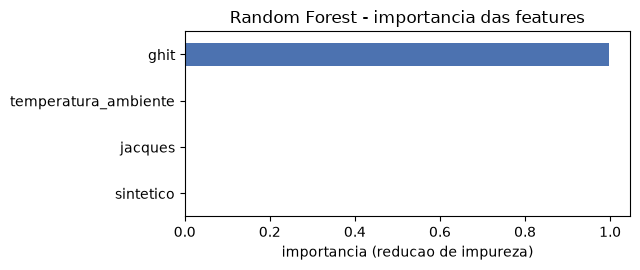

sintetico               0.0000
jacques                 0.0004
temperatura_ambiente    0.0027
ghit                    0.9969


In [9]:
importancia = pd.Series(rf_modelo.feature_importances_, index=FEATURES).sort_values()

ax = importancia.plot.barh(figsize=(6.5, 2.8), color="#4c72b0")
ax.set_xlabel("importancia (reducao de impureza)")
ax.set_title("Random Forest - importancia das features")
plt.tight_layout()
plt.show()

print(importancia.round(4).to_string())

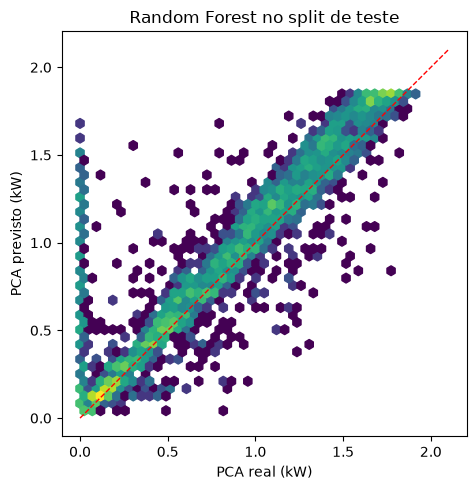

In [10]:
fig, eixo = plt.subplots(figsize=(6.5, 5))
eixo.hexbin(y_tes, pred_rf, gridsize=45, bins="log", cmap="viridis", extent=(0, 2.1, 0, 2.1))
eixo.plot([0, 2.1], [0, 2.1], "r--", lw=1)
eixo.set_xlabel("PCA real (kW)")
eixo.set_ylabel("PCA previsto (kW)")
eixo.set_title("Random Forest no split de teste")
eixo.set_aspect("equal")
plt.tight_layout()
plt.show()

## 7. Geração do código C

O `emlearn` escreve o C da floresta. Duas estratégias, com tamanho **medido no ESP32-S3**
(seção 9 para o método de medição):

| método | o que gera | flash | RAM | depende de |
|---|---|---|---|---|
| **`inline`** | um `if/else` por nó, direto no código | **67,6 KB** | 0 | nada além de `stdint.h` |
| `loadable` | arrays de nós percorridos por um interpretador | 39 KB | 28 B | `eml_trees.h` e `eml_common.h` |

O `loadable` economiza 54 KB, e a tentação é grande. A escolha aqui é **`inline`** mesmo
assim, por dois motivos:

1. **A quantização do `loadable` não está verificada.** Ele só aceita features `int16_t`, e
   os limiares de corte da árvore viram inteiros também. Numa floresta treinada em z-scores
   quebrados (`features[2] < -0.043423`), isso exige escolher uma escala e provar que
   nenhum limiar se desloca. Este notebook não faz essa prova — e um limiar deslocado não
   dá erro, dá previsão pior em silêncio.
2. **54 KB não pesam aqui.** O ESP32-S3 tem 16 MB de flash e o modelo atual do Edge Impulse
   ocupa ~112 KB. A troca não é entre caber e não caber.

Se um dia o flash apertar, é trocar `method='inline'` por `method='loadable'` e adicionar a
quantização — mas aí a verificação da seção 9 precisa rodar de novo, com a escala no lugar.

> **Correção (2026-10-11):** o flash real medido é **67,6 KB** (69 252 bytes, `xtensa-size` com
> `-O2`) — a seção 9 sempre imprimiu esse número; a tabela acima é que dizia 93 KB. A coluna do
> `loadable` (~39 KB) **não foi re-medida** nesta sessão; se ela valer, a economia deixa de ser
> 54 KB e passa a ~29 KB, e a conclusão (o ESP32-S3 tem 16 MB de flash; a troca não é entre caber
> e não caber) não muda.


## 8. A biblioteca do PlatformIO

O modelo é entregue como uma **biblioteca do PlatformIO em `lib/knob-senses-rf/`**, na
mesma forma da `lib/knob-senses/` que veio do Edge Impulse:

```
lib/knob-senses-rf/
  library.json        manifesto do PlatformIO (nome, versao, frameworks)
  normalizacao.json   as constantes de z-score, para o Python ler
  README.md           o contrato e o custo, para quem for usar
  src/
    knob_senses_rf.h    API publica e os numeros de procedencia
    knob_senses_rf.cpp  implementacao: z-score, floresta, clip
    modelo_pca.h        as arvores, geradas pelo emlearn (nao editar)
```

O `normalizacao.json` grava as constantes que estão **compiladas dentro do C**. O firmware
não lê esse arquivo — ele existe para quem for conferir ou reproduzir a normalização fora
do C (o próprio notebook, um teste do lado do servidor), de modo que as constantes nunca
precisem ser transcritas à mão. Constante transcrita envelhece sozinha, e a que envelhece
errado não avisa.

O `platformio.ini` já tem `lib_ldf_mode = deep+`, então a lib é encontrada sem nenhuma
mudança de configuração — basta incluir o header.

**A API é uma função:**

```c
float pca_prever(const float bruto[KNOB_RF_N_FEATURES]);
```

Ela recebe as 6 grandezas **brutas**, normaliza, roda a floresta e devolve kW já ceifado na
faixa física. O firmware não precisa saber que existe normalização.

> Este notebook **escreve dentro de `lib/`**, que é diretório de código versionado. A
> próxima execução sobrescreve `src/`, `README.md` e `library.json` — não edite à mão.

### O que muda em relação à biblioteca do Edge Impulse

A `lib/knob-senses/` exporta `run_classifier(signal_t*, ei_impulse_result_t*, bool)`, com
`result.classification[0].value` e os tempos em `result.timing`. Esta lib **não** imita essa
API, de propósito:

- **não há `signal_t` nem janela.** A floresta decide com uma amostra; a janela de 12
  amostras que o `main.cpp` mantém existe para o modelo do Edge Impulse, que é uma rede.
  Aqui ela é desnecessária — e manter a filtragem por janela seria herança, não requisito.
- **não há `timing.dsp` nem `timing.classification`.** Não existem estágios separados:
  é uma chamada de função. Inventar esses campos seria fingir uma arquitetura que não está
  lá, e o `printResult()` do `main.cpp` mostraria número falso.

Ou seja: quem for trocar o modelo no firmware precisa mexer no `main.cpp` — a troca não é
só de `#include`. A seção 10 diz o que muda.

In [11]:
escritos = rf.generate_c_lib(rf_modelo, MEDIA, DESVIO,
                     resultados[1]["MAE (kW)"], resultados[1]["R2"])
for caminho in sorted(escritos):
    print(f"  {caminho.relative_to(RAIZ)!s:44} {escritos[caminho]:,} bytes")
print("\nOK: nenhum marcador sobrou nos arquivos gerados")


  lib\knob-senses-rf\library.json              508 bytes
  lib\knob-senses-rf\normalizacao.json         944 bytes
  lib\knob-senses-rf\README.md                 2,361 bytes
  lib\knob-senses-rf\src\knob_senses_rf.cpp    1,244 bytes
  lib\knob-senses-rf\src\knob_senses_rf.h      2,343 bytes

OK: nenhum marcador sobrou nos arquivos gerados


### O header público

Vale ver o contrato inteiro — é o que quem for usar a lib lê primeiro.

In [12]:
print((SRC / "knob_senses_rf.h").read_text(encoding="utf-8"))

/*
 * knob-senses - Random Forest de regressao de PCA (potencia CA do inversor, kW).
 *
 * GERADO POR utils/treino_random_forest.ipynb. NAO EDITE A MAO: a proxima execucao
 * do notebook sobrescreve este arquivo.
 *
 * Como usar:
 *
 *     #include <knob_senses_rf.h>
 *
 *     const float bruto[KNOB_RF_N_FEATURES] = { 26.1f, 480.0f, 310.5f, 38.7f,
 *                                               sin1, cos1 };
 *     const float kw = pca_prever(bruto);
 *
 * ORDEM DAS GRANDEZAS BRUTAS:
 *   bruto[0] = temperatura_ambiente
 *   bruto[1] = ghit
 *   bruto[2] = jacques
 *   bruto[3] = sintetico
 *
 * O modelo foi treinado em z-scores e a normalizacao vive DENTRO desta lib (ver
 * knob_senses_rf.cpp): passe a grandeza fisica como ela veio do sensor. Nao normalize
 * antes de chamar pca_prever() - se o dado chegar em z-score, a conta acontece duas
 * vezes, tudo cai a ~7 desvios-padrao da media, e a previsao COLAPSA num valor fixo.
 *
 * Custo no ESP32-S3: 67.6 KB de flash, 0 de RAM. A flore

## 9. Verificação: compilar e conferir contra o sklearn

Gerar o C e olhar o tamanho não prova nada. A prova é **compilar a biblioteca de verdade e
comparar com o sklearn**:

1. um `main` em C++ lê valores **brutos** pela entrada padrão e imprime `pca_prever(x)`;
2. o `g++` do host compila **junto com o `knob_senses_rf.cpp` da lib** — é o arquivo da
   entrega que está sendo testado, não uma cópia;
3. o notebook empurra o **bruto do split de teste** por ele;
4. e compara com o que a floresta do sklearn previu.

Isso valida de uma vez as três coisas que podem dar errado: as constantes de normalização,
as árvores geradas e o *clip*. Um erro em qualquer uma aparece como divergência.

**O que o teste NÃO pode exigir é igualdade exata.** O sklearn avalia as árvores em `float64`;
o C avalia em `float32` — e `float32` é o que o ESP32 tem. Uma amostra que caia a menos de um
épsilon de `float32` de um limiar de corte (`features[2] < -0.043423`) cai do outro lado, e a
folha muda. Então o esperado é: **quase todas as linhas no ruído, e um punhado de trocas de
folha.** O teste cobra isso, em vez de exatidão — que seria uma exigência impossível e
esconderia o número que interessa.

In [13]:
conferidor = rf_verify.write_checker()
exe = rf_verify.compile_host(conferidor)
print("g++: compilou o conferidor junto com o knob_senses_rf.cpp da lib")
print(f"     {exe.relative_to(RAIZ)}  {exe.stat().st_size / 1024:.1f} KB")


g++: compilou o conferidor junto com o knob_senses_rf.cpp da lib
     data\modelo_rf\verifica.exe  272.6 KB


In [14]:
# Empurra o BRUTO do teste (nao o z-score) pelo executavel.
do_c = rf_verify.predict(exe, BRUTO_TES)
veredito = rf_verify.compare(do_c, pred_rf, y_tes)

print(f"linhas conferidas: {veredito['linhas']}")
print(f"  diferenca mediana            : {veredito['mediana']:.2e} kW   (ruido de float32)")
print(f"  diferenca media              : {veredito['media']:.2e} kW")
print(f"  maior diferenca              : {veredito['maior']:.2e} kW")
print(f"  linhas que trocaram de folha : {veredito['trocas']}")

print()
resultados.append(evaluate("lib compilada", y_tes, do_c))
print("\nOK: a biblioteca reproduz a floresta treinada, com normalizacao e clip")


linhas conferidas: 4177
  diferenca mediana            : 5.59e-08 kW   (ruido de float32)
  diferenca media              : 5.26e-07 kW
  maior diferenca              : 1.88e-03 kW
  linhas que trocaram de folha : 1

lib compilada        MAE 0.1426 kW | RMSE 0.2571 kW | R2 0.7732 | vies +0.0970 kW

OK: a biblioteca reproduz a floresta treinada, com normalizacao e clip


In [15]:
print(f"{'modelo':>20} {'MAE':>9} {'RMSE':>9} {'R2':>9} {'MAE c/ clip':>12} {'vies':>9}")
print("-" * 72)
for r_ in resultados:
    print(f"{r_['modelo']:>20} {r_['MAE (kW)']:9.4f} {r_['RMSE (kW)']:9.4f} "
          f"{r_['R2']:9.4f} {r_['MAE com clip (kW)']:12.4f} {r_['vies (kW)']:+9.4f}")

              modelo       MAE      RMSE        R2  MAE c/ clip      vies
------------------------------------------------------------------------
     media do treino    0.4704    0.5422   -0.0091       0.4704   +0.0514
       random forest    0.1426    0.2571    0.7732       0.1426   +0.0970
       lib compilada    0.1426    0.2571    0.7732       0.1426   +0.0970


### O teste do caminho da rede

A verificação acima compara a lib com o sklearn, mas alimenta o conferidor com `BRUTO_TES`
— um array montado aqui dentro. Isso não prova nada sobre o que **chega** na lib em campo.

Esta seção percorre o caminho inteiro, do jeito que ele vai rodar: lê o `test.csv` como o
`server.ipynb` lê, manda os valores pela entrada padrão do conferidor (é o que o socket faz)
e compara com o PCA real.

Vale a pena porque este contrato já foi violado uma vez, e o sintoma era cruel: quando os
csv ainda vinham em z-score, o servidor os mandava como estavam, o `pca_prever()` normalizava
de novo, e a previsão **colapsava num valor fixo** — `pred` idêntico em todas as linhas, com
a entrada variando. Nenhum teste offline pegava, porque o defeito não estava em nenhum dos
dois lados isoladamente: estava no contrato entre eles.

In [16]:
# Le o csv exatamente como o model_teste.ipynb le - verbatim, sem tocar nos valores.
amostra = data.read_csv(PROCESSADO / "test.csv")
bruto_rede = amostra[list(FEATURES)].to_numpy(np.float64)

pela_rede = rf_verify.predict(exe, bruto_rede)

erro = np.abs(pela_rede - amostra[ALVO].to_numpy())
amplitude = float(pela_rede.max() - pela_rede.min())

print(f"o caminho inteiro, nas {len(amostra)} linhas de test.csv:")
print(f"  MAE        : {erro.mean():.4f} kW")
print(f"  amplitude  : {amplitude:.4f} kW")
print(f"  primeira   : real {amostra[ALVO].iloc[0]:.4f}  previsto {pela_rede[0]:.4f}")

# Duas guardas. A primeira pega contrato quebrado em geral; a segunda pega o sintoma
# especifico de normalizacao dupla, que e' a previsao ficar praticamente constante.
assert erro.mean() < 0.25, (
    f"MAE {erro.mean():.4f} kW pelo caminho da rede - o contrato quebrou")
assert amplitude > 0.1, (
    f"amplitude {amplitude:.5f} kW: a previsao ficou praticamente constante. "
    "Quase sempre e' normalizacao aplicada duas vezes - confira se data/processed/*.csv "
    "nao voltou a sair em z-score.")

print("\nOK: o caminho csv -> rede -> lib devolve previsao util")


o caminho inteiro, nas 4177 linhas de test.csv:
  MAE        : 0.1426 kW
  amplitude  : 1.7915 kW
  primeira   : real 0.0817  previsto 0.1005

OK: o caminho csv -> rede -> lib devolve previsao util


### O tamanho real no ESP32-S3

Compilar no host prova a matemática. Para saber **quanto ocupa de flash**, o teste é
compilar o `.cpp` da lib com o toolchain do próprio ESP32 e medir.

Um cuidado que custa caro se passar batido: **somar as seções do `size -A` dá um número
errado**. O `.literal` (o depósito de constantes float do Xtensa) é `ALLOC, LOAD` e vai
para o flash, mas não se chama `.text` — somar só `.text + .rodata + .data` esquece 25 KB.
Do outro lado, o `.xt.prop` **não** é `ALLOC` e morre no link. O número confiável é o do
`size` sem `-A`, que já faz a conta certa.

In [17]:
medida = rf_verify.measure_xtensa()
for nome, tamanho in medida["secoes"].items():
    print(f"  {nome:16} {tamanho:7} bytes")

flash, ram = medida["flash"], medida["ram"]
print(f"\n  FLASH  {flash:7} bytes  ({flash / 1024:.1f} KB)")
print(f"  RAM    {ram:7} bytes")
print(f"\n  para comparar: o modelo do Edge Impulse no firmware ocupa ~112 KB")

if ram:
    print(f"\n  ATENCAO: {ram} bytes de RAM. Esperado era zero - o emlearn emite as")
    print("  arvores como codigo, nao como tabela. Confira o que foi para .data/.bss.")
else:
    print("\n  RAM zero: a floresta e' toda constante e vive no flash.")


  .literal           18692 bytes
  .text              52023 bytes
  .data                  0 bytes
  .bss                   0 bytes
  .comment              45 bytes
  .xtensa.info          56 bytes
  .xt.lit                8 bytes
  .xt.prop           29628 bytes

  FLASH    70715 bytes  (69.1 KB)
  RAM          0 bytes

  para comparar: o modelo do Edge Impulse no firmware ocupa ~112 KB

  RAM zero: a floresta e' toda constante e vive no flash.


O `.bss`/`.data` zerados não são acidente: o `emlearn` emite as árvores como código
(`inline`), não como tabela em RAM. A floresta inteira mora no flash e é lida direto de lá,
que é o comportamento que se quer num microcontrolador.

Em compensação, o `inline` **troca flash por velocidade**: o `if/else` de cada nó é
executado sem indireção de ponteiro. É essa troca que explica a distância para o
`loadable` da seção 7 — 67,6 KB contra ~39 KB (o número do `loadable` não foi re-medido nesta sessão).

## 10. Resumo

### A entrega

`lib/knob-senses-rf/` — biblioteca do PlatformIO, na mesma forma da `lib/knob-senses/` do
Edge Impulse:

| arquivo | para que serve |
|---|---|
| `src/knob_senses_rf.h` | **é este que o firmware inclui.** API, ordem das features, números de procedência |
| `src/knob_senses_rf.cpp` | z-score + floresta + clip |
| `src/modelo_pca.h` | as árvores, geradas pelo emlearn. Não editar |
| `normalizacao.json` | as constantes que estão compiladas dentro do C. Registro, não configuração |
| `library.json` | manifesto do PlatformIO |
| `README.md` | o contrato e o custo, para quem for usar a lib |

O `data/modelo_rf/` guarda só o conferidor e o resíduo de build — não é entrega.

### A regra

**Entrega-se grandeza física; a normalização é do MCU.** `data/processed/*.csv` estão em
graus e W/m², o `server.ipynb` manda o csv verbatim, e o `pca_prever()` faz a conta. Se a
previsão sair **constante** com a entrada variando, é normalização aplicada duas vezes.

### Como ligar no firmware

O `platformio.ini` já tem `lib_ldf_mode = deep+`, então a lib é encontrada sozinha. A troca
no `src/main.cpp` **não é só de `#include`** — a forma do modelo é outra:

| hoje (Edge Impulse) | com a lib do RF |
|---|---|
| janela de `kSamples × kAxes` floats | **uma amostra de 6 floats** |
| `runInference(frame, ei_impulse_result_t*)` | `pca_prever(bruto)` |
| `result.classification[0].value` | o próprio retorno da função |
| `result.timing.dsp` / `timing.classification` | não existe — é uma chamada de função |

Os pontos concretos:

1. **A janela circular de 12 amostras deixa de ser necessária.** A floresta decide com uma
   amostra; a janela existe para a rede. Manter a espera de `g_filled < kSamples` só
   atrasaria a primeira previsão sem ganho nenhum.
2. **Nada de normalizar antes de chamar.** A lib faz a conta. Se um dia o device passar a
   ler sensor de verdade, ele passa a grandeza física direto — sem z-score no meio.
3. **`printResult()` precisa de ajuste**, porque imprime `timing.dsp` e `timing.classification`.

> **Correção de uma afirmação errada da primeira versão deste notebook.** Eu escrevi que o
> caminho do Edge Impulse sofria de "o firmware manda bruto, mas o modelo espera z-score".
> **Não sofria** — na época o `server.ipynb` mandava z-scores e o modelo do Edge Impulse
> também esperava z-scores; aquele caminho estava correto. Eu tinha me baseado no comentário
> do `main.cpp` ("Mande valores BRUTOS"), que descreve o fluxo antigo de 9 eixos, sem
> conferir contra o `server.ipynb`. A premissa era falsa, ainda que o contrato que ela
> acabou produzindo — entra bruto, normaliza no MCU — seja o certo.

Isso é uma reescrita do caminho de aquisição do `main.cpp`, não um patch de duas linhas — e
o `main.cpp` está com alterações em andamento, então este notebook não o toca.